# Лабораторная работа 3 Регрессионный анализ

Жойд Станислав Вадимович, группа 4417, вариант 8. Дисциплина «Анализ данных».

Цель работы - изучить на практике алгоритмы регрессии, сравнить качество моделей и объяснить полученные результаты.

Используются лист `var8` файла `regression.xlsx` и таблица `salary.csv`. Файлы `regression.xlsx` и `salary.csv` загружаются из каталога ноутбука, папки `utility` или папки «Загрузки». Все преобразования обучаются только по тренировочным данным. Разбиение воспроизводится с `random_state=8`, соответствующим номеру варианта.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, PolynomialFeatures
from sklearn.tree import DecisionTreeRegressor

SEED = 8

pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', '{:.5f}'.format)

plt.rcParams.update(
    {'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.grid': True, 'grid.alpha': 0.2}
)


def data_file(name):
    for folder in [Path.cwd(), Path.cwd() / 'utility', Path.home() / 'Downloads']:
        path = folder / name
        if path.is_file():
            return path
    raise FileNotFoundError(f'Поместите {name} рядом с ноутбуком или в папку «Загрузки».')


def metrics(y, prediction):
    return {
        'MAE': mean_absolute_error(y, prediction),
        'MSE': mean_squared_error(y, prediction),
        'RMSE': np.sqrt(mean_squared_error(y, prediction)),
        'R2': r2_score(y, prediction)
    }


def fact_prediction(ax, y, prediction, title):
    ax.scatter(y, prediction, s=13, alpha=0.6)

    limits = [min(np.min(y), np.min(prediction)), max(np.max(y), np.max(prediction))]

    ax.plot(limits, limits, color='red', label='Идеальный прогноз')

    ax.set(xlabel='Фактическое значение', ylabel='Прогноз', title=title, xlim=limits, ylim=limits)
    ax.set_aspect('equal', adjustable='box')
    ax.legend(fontsize=8)

# 1 Простая линейная регрессия

## 1.1 Исходные данные и корреляции

Загружен лист `var8`. Функция `describe()` показывает объём выборки, средние значения, разброс и квартили. Корреляция Пирсона оценивает только линейную связь и не доказывает причинность.

In [2]:
reg = pd.read_excel(data_file('regression.xlsx'), sheet_name='var8')

display(reg.head())
display(reg.describe())
display(reg.corr(method='pearson'))

print('Пропуски:', reg.isna().sum().to_dict())
print('Дубликаты:', int(reg.duplicated().sum()))

,x1,x2,y
0,-1.65571,1.20458,2.77791
1,-0.46174,1.49421,0.59487
2,0.82342,-1.02407,-1.41403
3,0.90086,0.44011,0.10488
4,0.51141,-1.75304,-1.38714


,x1,x2,y
count,1000.00000,1000.00000,1000.00000
mean,-0.00002,-0.00001,0.41062
std,1.15525,1.15528,1.06084
min,-1.99730,-1.99732,-2.24819
25%,-0.99969,-0.99805,-0.38055
50%,0.00050,0.00092,0.36008
75%,0.99961,0.99893,1.15656
max,1.99721,1.99956,4.07737


,x1,x2,y
x1,1.00000,-0.01499,-0.33370
x2,-0.01499,1.00000,0.59327
y,-0.33370,0.59327,1.00000


Пропуски: {'x1': 0, 'x2': 0, 'y': 0}
Дубликаты: 0


Коэффициент корреляции x1 с y равен −0,33370: линейная связь отрицательная и сравнительно слабая. Для x2 получено 0,59327: положительная связь выражена сильнее. Между x1 и x2 почти нет линейной связи (−0,01499). По одному коэффициенту корреляции нельзя исключить нелинейную зависимость.

## 1.2 Обучение моделей и оценка

Для обеих моделей использовано одно разбиение: 75% наблюдений для обучения и 25% для проверки. Модель имеет вид y = a·x + b. MAE измеряет среднюю абсолютную ошибку, MSE - средний квадрат ошибки, RMSE выражает ошибку в единицах y. R² сравнивает сумму квадратов ошибок с разбросом фактических значений; отрицательный R² означает качество хуже постоянного прогноза среднего проверочной выборки.

In [3]:
train_idx, valid_idx = train_test_split(reg.index, test_size=0.25, random_state=SEED)

simple_models = {}
simple_rows = []
simple_predictions = pd.DataFrame({'y': reg.loc[valid_idx, 'y']})

for feature in ['x1', 'x2']:
    model = LinearRegression()
    model.fit(reg.loc[train_idx, [feature]], reg.loc[train_idx, 'y'])

    prediction = model.predict(reg.loc[valid_idx, [feature]])

    simple_models[feature] = model
    simple_predictions[feature] = prediction
    simple_rows.append(
        {
            'Признак': feature,
            'a': model.coef_[0],
            'b': model.intercept_,
            **metrics(reg.loc[valid_idx, 'y'], prediction)
        }
    )

    comparison = pd.DataFrame(
        {
            'Факт': reg.loc[valid_idx, 'y'],
            'Прогноз': prediction,
            'Прогноз минус факт': prediction - reg.loc[valid_idx, 'y']
        }
    )
    display(comparison)

simple_metrics = pd.DataFrame(simple_rows)

display(simple_metrics)
print('Обучение:', len(train_idx), 'Проверка:', len(valid_idx))

,Факт,Прогноз,Прогноз минус факт
908,-1.14724,0.53743,1.68467
265,0.19670,0.46151,0.26481
627,1.16416,0.35498,-0.80918
327,0.90556,0.19250,-0.71306
244,-0.09743,0.62243,0.71986
...,...,...,...
288,-0.92302,0.30298,1.22600
335,1.80301,0.56913,-1.23388
510,1.54253,0.42128,-1.12125
836,0.29990,0.16106,-0.13884


,Факт,Прогноз,Прогноз минус факт
908,-1.14724,-0.49108,0.65616
265,0.19670,0.86284,0.66613
627,1.16416,1.40326,0.23910
327,0.90556,1.15350,0.24794
244,-0.09743,1.09700,1.19443
...,...,...,...
288,-0.92302,0.21333,1.13635
335,1.80301,1.49490,-0.30812
510,1.54253,1.42229,-0.12023
836,0.29990,0.66376,0.36386


,Признак,a,b,MAE,MSE,RMSE,R2
0,x1,-0.29034,0.40123,0.79922,0.93202,0.96541,0.14942
1,x2,0.54915,0.39972,0.66122,0.72872,0.85365,0.33495


Обучение: 750 Проверка: 250


## 1.3 Графики и ошибки

На первом рисунке представлены наблюдения и прямые, обученные на тренировочной выборке. Затем показана разность «прогноз − факт» для каждой проверочной точки. На графиках факт-прогноз красная диагональ обозначает идеальное совпадение. Одинаковые пределы и масштаб осей сохраняют угол 45°.

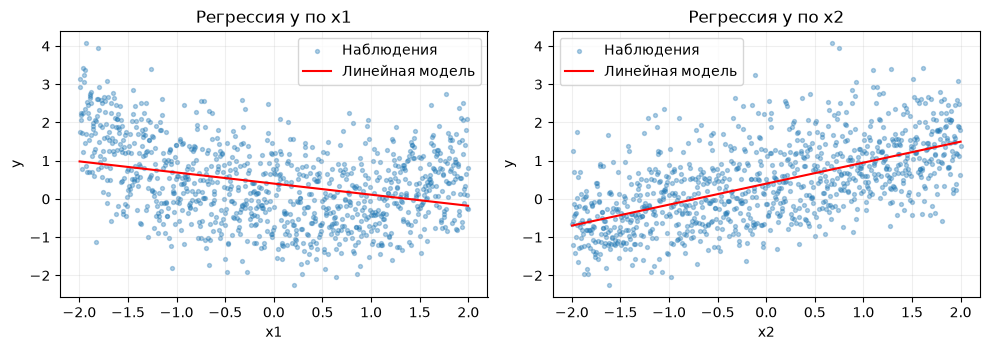

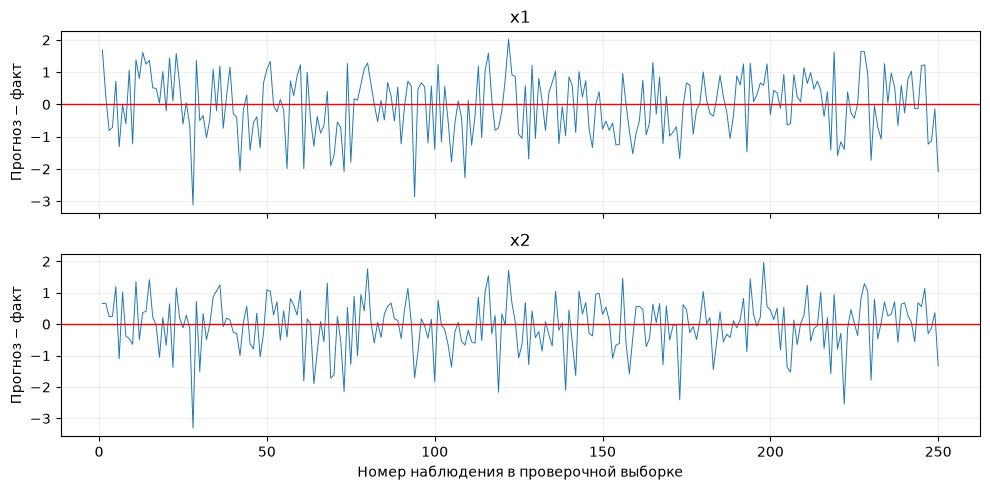

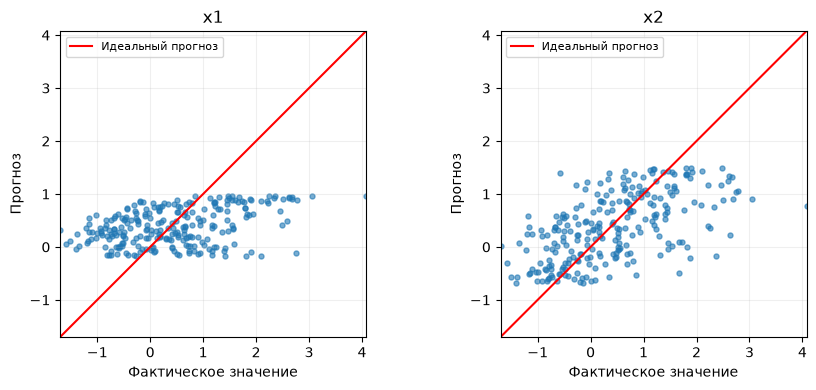

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))

for ax, feature in zip(axes, ['x1', 'x2']):
    grid = np.linspace(reg[feature].min(), reg[feature].max(), 300)

    ax.scatter(reg[feature], reg.y, s=8, alpha=0.35, label='Наблюдения')

    ax.plot(
        grid,
        simple_models[feature].predict(pd.DataFrame({feature: grid})),
        color='red',
        label='Линейная модель'
    )

    ax.set(xlabel=feature, ylabel='y', title=f'Регрессия y по {feature}')
    ax.legend()

fig.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)

for ax, feature in zip(axes, ['x1', 'x2']):
    error = simple_predictions[feature] - simple_predictions.y

    ax.plot(np.arange(1, len(error) + 1), error.to_numpy(), linewidth=0.7)
    ax.axhline(0, color='red', linewidth=1)

    ax.set(ylabel='Прогноз − факт', title=feature)

axes[-1].set_xlabel('Номер наблюдения в проверочной выборке')

fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

for ax, feature in zip(axes, ['x1', 'x2']):
    fact_prediction(ax, simple_predictions.y, simple_predictions[feature], feature)

fig.tight_layout()
plt.show()

# 2 Полиномиальная регрессия

Для полинома выбран x1: диаграмма рассеяния показывает изгиб зависимости, который одна прямая не описывает. Для x2 основной тренд близок к линейному. Сравниваются степени 2, 3, 5 и 10, а степень 1 служит исходным ориентиром. PolynomialFeatures создаёт степени признака без отдельного столбца единиц; свободный член задаёт LinearRegression.

Степень выбирается по средней MAE при пятикратной перекрёстной проверке только на обучающей выборке. Проверочные 250 наблюдений не участвуют в этом выборе. Затем для всех степеней показаны MAE и R² на обеих выборках.

,Степень,R2_train,R2_valid,MAE_train,MAE_valid,MAE_CV
0,1,0.09849,0.14942,0.82895,0.79922,0.83202
1,2,0.29088,0.30054,0.72472,0.73346,0.72904
2,3,0.29103,0.29872,0.72440,0.73444,0.73076
3,5,0.29575,0.30864,0.72115,0.73360,0.72863
4,10,0.29873,0.30037,0.71988,0.73618,0.73001


Степень с минимальной MAE_CV: 5


,x1,Факт,Прогноз
908,-0.46909,-1.14724,0.19929
265,-0.20761,0.19670,0.03342
627,0.15929,1.16416,-0.15681
327,0.71894,0.90556,-0.21433
244,-0.76187,-0.09743,0.39471
...,...,...,...
288,0.33840,-0.92302,-0.21416
335,-0.57829,1.80301,0.27130
510,-0.06905,1.54253,-0.04684
836,0.82722,0.29990,-0.17851


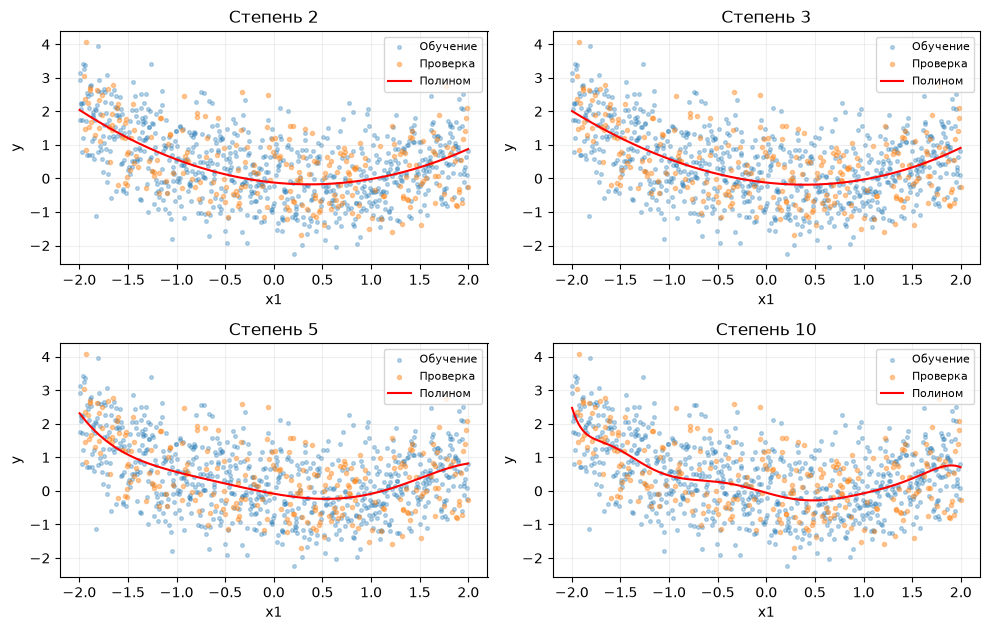

In [5]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

poly_rows = []
poly_models = {}

for degree in [1, 2, 3, 5, 10]:
    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )

    cv_mae = -cross_val_score(
        model,
        reg.loc[train_idx, ['x1']],
        reg.loc[train_idx, 'y'],
        cv=cv,
        scoring='neg_mean_absolute_error',
        n_jobs=1
    ).mean()

    model.fit(reg.loc[train_idx, ['x1']], reg.loc[train_idx, 'y'])

    train_prediction = model.predict(reg.loc[train_idx, ['x1']])
    valid_prediction = model.predict(reg.loc[valid_idx, ['x1']])

    poly_models[degree] = model
    poly_rows.append(
        {
            'Степень': degree,
            'R2_train': r2_score(reg.loc[train_idx, 'y'], train_prediction),
            'R2_valid': r2_score(reg.loc[valid_idx, 'y'], valid_prediction),
            'MAE_train': mean_absolute_error(reg.loc[train_idx, 'y'], train_prediction),
            'MAE_valid': mean_absolute_error(reg.loc[valid_idx, 'y'], valid_prediction),
            'MAE_CV': cv_mae
        }
    )

poly_metrics = pd.DataFrame(poly_rows)
best_degree = int(poly_metrics.loc[poly_metrics.MAE_CV.idxmin(), 'Степень'])

display(poly_metrics)
print('Степень с минимальной MAE_CV:', best_degree)

poly_prediction = poly_models[best_degree].predict(reg.loc[valid_idx, ['x1']])
poly_comparison = pd.DataFrame(
    {'x1': reg.loc[valid_idx, 'x1'], 'Факт': reg.loc[valid_idx, 'y'], 'Прогноз': poly_prediction}
)
display(poly_comparison)

fig, axes = plt.subplots(2, 2, figsize=(10, 6.4))
grid = pd.DataFrame({'x1': np.linspace(reg.x1.min(), reg.x1.max(), 400)})

for ax, degree in zip(axes.flat, [2, 3, 5, 10]):
    ax.scatter(reg.loc[train_idx, 'x1'], reg.loc[train_idx, 'y'], s=7, alpha=0.3, label='Обучение')
    ax.scatter(reg.loc[valid_idx, 'x1'], reg.loc[valid_idx, 'y'], s=9, alpha=0.4, label='Проверка')

    ax.plot(grid.x1, poly_models[degree].predict(grid), color='red', label='Полином')

    ax.set(xlabel='x1', ylabel='y', title=f'Степень {degree}')
    ax.legend(fontsize=8)

fig.tight_layout()
plt.show()

Оптимальная степень определяется по данным и выбранной метрике, а не задаётся универсальным числом. Слишком низкая степень не описывает изгиб и приводит к недообучению. Слишком высокая может подстраиваться под случайный шум, повышать нестабильность коэффициентов и ухудшать прогноз вне наблюдавшегося диапазона. Само увеличение степени ещё не доказывает переобучение: вывод должен опираться на проверочные ошибки.

Минимум MAE перекрёстной проверки получен при степени 5. Её преимущество над степенью 2 составляет лишь около 0,00041, поэтому убедительного выигрыша от усложнения нет. Степень 2 остаётся практически сопоставимым более простым вариантом.

# 3 Прогноз годовой зарплаты

## 3.1 Проверка исходного набора

Целевой столбец - salary. Остальные 14 столбцов описывают возраст, предыдущий доход, опыт, тест, рабочее время, расстояние, сбережения, долги и категории сотрудников. income не является целевой переменной: это доход до текущей работы.

,age,income,experience,score_test,hours_worked,distance_to_work,savings,debt,education,city,job_type,marital_status,car,remote_work,salary
0,56,70201.18968,25,87.55973,62,3.70869,25987.33405,2556.82163,PhD,Chicago,Finance,Single,Yes,Yes,106233.83348
1,69,51901.89740,39,70.80838,36,7.08279,22134.89902,725.18051,High School,Houston,Retail,Single,No,Yes,87205.29104
2,46,38605.40929,4,63.32500,77,5.12915,47106.06841,12659.35958,PhD,Los Angeles,Finance,Married,Yes,No,69369.28352
3,32,49949.73696,20,78.21551,33,19.31562,15868.32881,12369.77600,Bachelor,Los Angeles,IT,Married,Yes,No,76587.11696
4,60,48965.29009,13,74.42910,48,5.65490,15734.63333,4792.09521,Bachelor,Phoenix,IT,Married,No,No,71023.14884


,age,income,experience,score_test,hours_worked,distance_to_work,savings,debt,education,city,job_type,marital_status,car,remote_work,salary
count,1500.00000,1500.00000,1500.00000,1500.00000,1500.00000,1500.00000,1500.00000,1500.00000,1500,1500,1500,1500,1500,1500,1500.00000
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,5,5,3,2,2,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Bachelor,New York,Retail,Married,Yes,Yes,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,900,600,500,717,1050,883,NaN
mean,43.73200,50493.56217,19.47933,74.64987,49.04600,10.16917,19920.72304,7656.74931,NaN,NaN,NaN,NaN,NaN,NaN,98573.09352
std,15.07177,15354.49571,11.47153,9.90443,17.05365,10.00309,13635.53011,5481.39040,NaN,NaN,NaN,NaN,NaN,NaN,111786.75600
min,18.00000,-826.42124,0.00000,41.60500,20.00000,0.01814,408.48201,4.36713,NaN,NaN,NaN,NaN,NaN,NaN,28588.98426
25%,31.00000,40525.98972,10.00000,67.77613,34.00000,3.02216,9418.70791,3138.48422,NaN,NaN,NaN,NaN,NaN,NaN,69582.65490
50%,44.00000,50784.69057,19.00000,74.70157,49.00000,7.10517,17114.51252,6786.70378,NaN,NaN,NaN,NaN,NaN,NaN,80310.41280
75%,56.00000,61104.99796,29.00000,81.63563,63.00000,14.39207,27766.21400,11008.30957,NaN,NaN,NaN,NaN,NaN,NaN,91637.05260


Размер: (1500, 15)
Пропуски: 0
Повторы: 0
Отрицательный income: 1


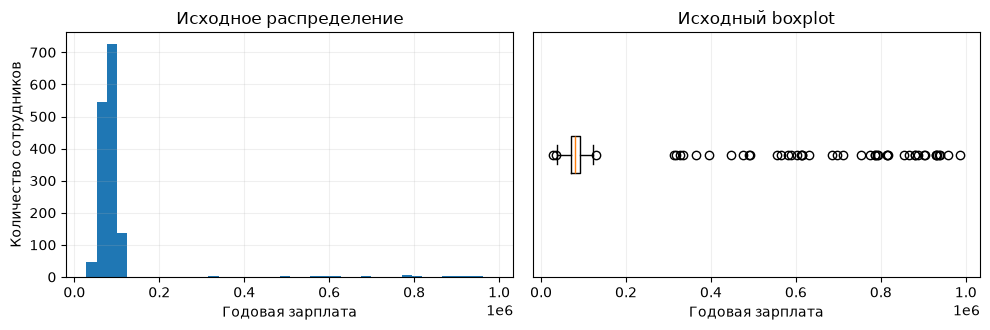

In [6]:
salary = pd.read_csv(data_file('salary.csv'))

display(salary.head())
display(salary.describe(include='all'))

print('Размер:', salary.shape)
print('Пропуски:', salary.isna().sum().sum())
print('Повторы:', salary.duplicated().sum())
print('Отрицательный income:', int((salary.income < 0).sum()))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))

axes[0].hist(salary.salary, bins=40)
axes[
    0
].set(xlabel='Годовая зарплата', ylabel='Количество сотрудников', title='Исходное распределение')

axes[1].boxplot(salary.salary, orientation='horizontal')
axes[1].set(xlabel='Годовая зарплата', title='Исходный boxplot', yticks=[])

fig.tight_layout()
plt.show()

## 3.2 Разбиение и обработка

Пропусков и точных повторов нет. Одно отрицательное значение income заменено на пропуск; медиана для его заполнения оценивается внутри обучаемого конвейера. Для остальных числовых признаков не вводятся неподтверждённые границы: например, шкала score_test в описании не задана.

Сначала выделено 25% наблюдений для проверки. Границы salary по правилу 1,5 межквартильного размаха рассчитаны только на обучающей части. Наблюдения за этими границами исключены только из обучения. Проверочная выборка остаётся полной, включая экстремальные зарплаты. Это сохраняет честную оценку задачи на исходном распределении. Отдельно приведены условные метрики для проверочных зарплат внутри обучающих границ; они не заменяют основную оценку.

Границы: 36054.25358; 125557.88237
Обучение: 1125 → 1088; исключено 37
Проверка: 375; за границами 11


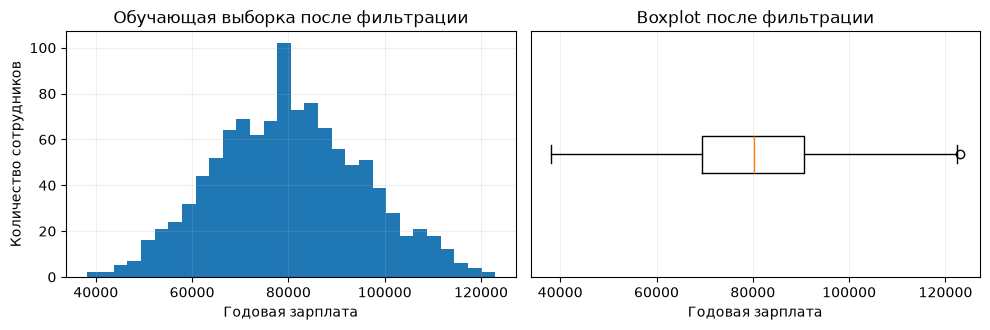

In [7]:
X = salary.drop(columns='salary').copy()
y = salary.salary.copy()
X.loc[X.income < 0, 'income'] = np.nan

X_train_raw, X_valid, y_train_raw, y_valid = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=SEED
)

q1, q3 = y_train_raw.quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr

keep_train = y_train_raw.between(lower, upper)
keep_valid = y_valid.between(lower, upper)

X_train, y_train = X_train_raw.loc[keep_train], y_train_raw.loc[keep_train]

print(f'Границы: {lower:.5f}; {upper:.5f}')
print(f'Обучение: {len(X_train_raw)} → {len(X_train)}; исключено {int((~keep_train).sum())}')
print(f'Проверка: {len(X_valid)}; за границами {int((~keep_valid).sum())}')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))

axes[0].hist(y_train, bins=30)
axes[
    0
].set(xlabel='Годовая зарплата', ylabel='Количество сотрудников', title='Обучающая выборка после фильтрации')

axes[1].boxplot(y_train, orientation='horizontal')
axes[1].set(xlabel='Годовая зарплата', title='Boxplot после фильтрации', yticks=[])

fig.tight_layout()
plt.show()

## 3.3 Матрица диаграмм рассеяния

Для восьми числовых предикторов и salary построена полная матрица диаграмм рассеяния на очищенной обучающей части. Диагональ содержит гистограммы. Предикторы сохраняют исходные масштабы. Связи оцениваются как наблюдаемые зависимости, без причинных выводов.

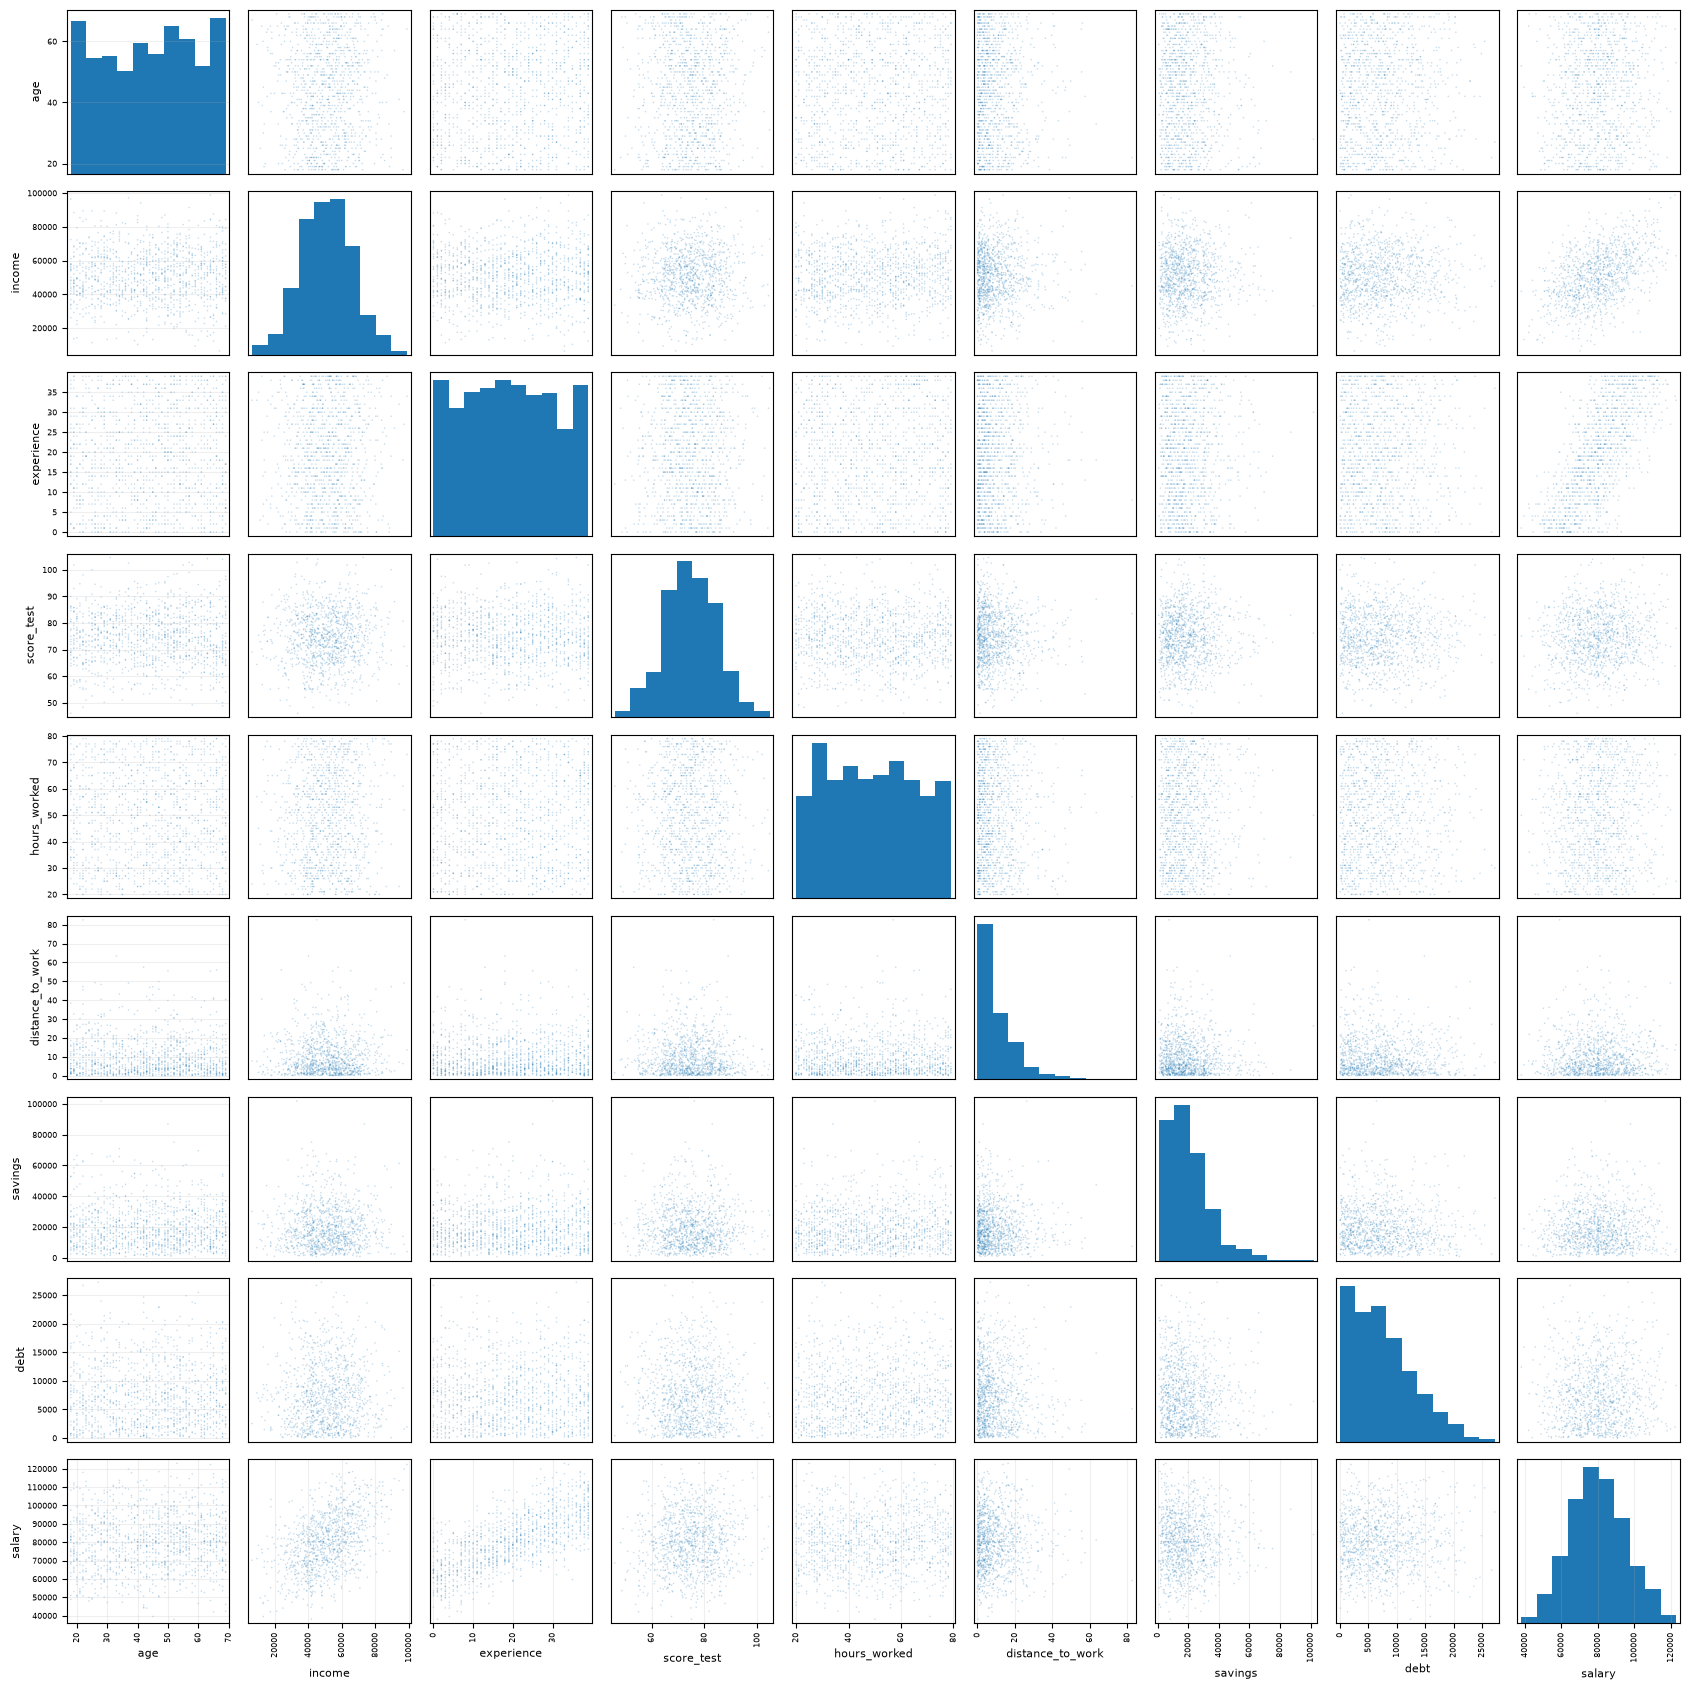

In [8]:
numeric = X.select_dtypes(include='number').columns.tolist()
categorical = X.select_dtypes(exclude='number').columns.tolist()

scatter_data = X_train[numeric].copy()
scatter_data['salary'] = y_train

axes = pd.plotting.scatter_matrix(
    scatter_data,
    figsize=(17, 17),
    diagonal='hist',
    alpha=0.25,
    s=5,
    grid=False
)

for ax in axes.flat:
    ax.tick_params(labelsize=6)
    ax.xaxis.label.set_size(8)
    ax.yaxis.label.set_size(8)

plt.tight_layout()
plt.show()

## 3.4 Перевод категорий в числа и обучение

Категории городов, образования и других текстовых признаков переведены в столбцы из нулей и единиц с помощью OneHotEncoder. Для каждого признака одна категория принята за базовую.

Числовые признаки стандартизированы с помощью StandardScaler: после преобразования среднее обучающего столбца равно 0, а стандартное отклонение равно 1. Это особенно важно для kNN, который сравнивает расстояния между сотрудниками. Пропуски заполняются медианами обучающей выборки.

Зарплата в очищенной обучающей выборке отдельно нормализована с помощью MinMaxScaler в диапазон от 0 до 1. Границы взяты только из обучающей выборки. Перед сравнением с настоящими зарплатами прогнозы переведены обратно в исходные единицы. Нормализация меняет масштаб чисел, но не устраняет выбросы и не делает распределение нормальным.

Обучены три модели: линейная регрессия, kNN с 5 соседями и дерево решений глубиной до 6 с минимумом 5 наблюдений в листе. Для сравнения также рассчитаны прогноз медианой и линейная модель до удаления выбросов. Ниже показаны результаты нормализации зарплаты и проверка масштаба числовых признаков.

In [9]:
salary_scaler = MinMaxScaler()
y_train_scaled = salary_scaler.fit_transform(y_train.to_frame()).ravel()

salary_scale_example = pd.DataFrame({
    'Зарплата до нормализации': y_train,
    'Зарплата после нормализации': y_train_scaled
})
display(salary_scale_example.head())
print('Диапазон обучающей зарплаты после нормализации:',
      y_train_scaled.min(), y_train_scaled.max())

preprocess = ColumnTransformer(
    [
        (
            'num',
            make_pipeline(SimpleImputer(strategy='median'), StandardScaler()),
            numeric
        ),
        (
            'cat',
            OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False),
            categorical
        )
    ]
)

estimators = {
    'Линейная регрессия': LinearRegression(),
    'kNN': KNeighborsRegressor(n_neighbors=5, n_jobs=1),
    'Дерево решений': DecisionTreeRegressor(max_depth=6, min_samples_leaf=5, random_state=SEED)
}

salary_models = {}
salary_rows = []
central_rows = []
salary_predictions = pd.DataFrame({'Факт': y_valid})

for name, estimator in estimators.items():
    model = Pipeline([('prepare', clone(preprocess)), ('model', estimator)])
    model.fit(X_train, y_train_scaled)

    prediction_scaled = model.predict(X_valid)
    prediction = salary_scaler.inverse_transform(
        prediction_scaled.reshape(-1, 1)
    ).ravel()

    salary_models[name] = model
    salary_predictions[name] = prediction
    salary_rows.append({'Модель': name, **metrics(y_valid, prediction)})
    central_rows.append(
        {'Модель': name, **metrics(y_valid.loc[keep_valid], prediction[keep_valid.to_numpy()])}
    )

    comparison = pd.DataFrame(
        {'Факт': y_valid, 'Прогноз': prediction, 'Прогноз минус факт': prediction - y_valid}
    )

    display(Markdown(f'### {name}'))
    display(comparison)

unfiltered = Pipeline([('prepare', clone(preprocess)), ('model', LinearRegression())])
y_train_raw_scaled = salary_scaler.transform(y_train_raw.to_frame()).ravel()
unfiltered.fit(X_train_raw, y_train_raw_scaled)
unfiltered_prediction = salary_scaler.inverse_transform(
    unfiltered.predict(X_valid).reshape(-1, 1)
).ravel()

baseline_prediction = np.full(len(y_valid), y_train.median())

salary_rows.append({'Модель': 'Линейная до фильтрации', **metrics(y_valid, unfiltered_prediction)})
salary_rows.append({'Модель': 'Медиана обучения', **metrics(y_valid, baseline_prediction)})

salary_metrics = pd.DataFrame(salary_rows)
central_metrics = pd.DataFrame(central_rows)

display(salary_metrics)

display(Markdown('Условная оценка внутри обучающих границ salary'))
display(central_metrics)

numeric_transformer = salary_models['Линейная регрессия'].named_steps[
    'prepare'
].named_transformers_['num']
numeric_scaled = numeric_transformer.transform(X_train[numeric])
scale_check = pd.DataFrame({
    'Признак': numeric,
    'Среднее после стандартизации': numeric_scaled.mean(axis=0),
    'Стандартное отклонение после стандартизации': numeric_scaled.std(axis=0)
})
display(scale_check)


,Зарплата до нормализации,Зарплата после нормализации
860,81242.79036,0.50863
1208,107339.72901,0.81623
107,85992.41641,0.56461
1195,69388.38511,0.36890
344,72076.06692,0.40058


Диапазон обучающей зарплаты после нормализации: 0.0 1.0


### Линейная регрессия

,Факт,Прогноз,Прогноз минус факт
1237,83805.26117,82062.22552,-1743.03565
437,74046.77847,73763.88273,-282.89574
51,92644.34927,90192.99166,-2451.35761
579,78156.90694,87180.68130,9023.77436
238,92794.11330,88387.84897,-4406.26433
...,...,...,...
577,90997.34598,90890.66139,-106.68459
1207,90891.08574,99967.05684,9075.97110
506,93517.12909,96112.08577,2594.95668
1154,66397.32236,61763.94964,-4633.37271


### kNN

...

,Факт,Прогноз,Прогноз минус факт
1237,83805.26117,79739.58370,-4065.67747
437,74046.77847,62771.88316,-11274.89531
51,92644.34927,89744.40325,-2899.94602
579,78156.90694,84895.50863,6738.60169
238,92794.11330,93870.53122,1076.41793
...,...,...,...
577,90997.34598,84451.06905,-6546.27694
1207,90891.08574,99847.55742,8956.47167
506,93517.12909,90100.09865,-3417.03044
1154,66397.32236,62771.88316,-3625.43920


,Модель,MAE,MSE,RMSE,R2
0,Линейная регрессия,20699.02528,10953021511.22858,104656.68403,-0.00282
1,kNN,23468.53317,11039685547.93182,105069.90791,-0.01076
2,Дерево решений,22656.25285,10866842726.34834,104244.14960,0.00507
3,Линейная до фильтрации,36895.88371,11281109488.20017,106212.56747,-0.03286
4,Медиана обучения,27628.01047,11161887266.51880,105649.83325,-0.02194


Условная оценка внутри обучающих границ salary

,Модель,MAE,MSE,RMSE,R2
0,Линейная регрессия,4888.20241,35850364.85077,5987.51742,0.83460
1,kNN,7666.45642,92950315.47360,9641.07439,0.57117
2,Дерево решений,6998.76711,76051790.00459,8720.76774,0.64913


,Признак,Среднее после стандартизации,Стандартное отклонение после стандартизации
0,age,-0.00000,1.00000
1,income,-0.00000,1.00000
2,experience,-0.00000,1.00000
3,score_test,-0.00000,1.00000
4,hours_worked,0.00000,1.00000
5,distance_to_work,-0.00000,1.00000
6,savings,0.00000,1.00000
7,debt,0.00000,1.00000


## 3.5 Какие признаки связаны с зарплатой

Коэффициенты линейной модели показывают, как меняется прогноз зарплаты при изменении одного признака и фиксированных остальных. Положительный коэффициент повышает прогноз, отрицательный снижает.

Сначала коэффициенты переведены из нормализованной шкалы зарплаты в исходные единицы. Для числовых признаков показаны два варианта: изменение прогноза при увеличении признака на одно стандартное отклонение и на одну исходную единицу. Для образования, города и других категорий коэффициент показывает отличие от базовой категории. По таким данным оценивается связь внутри модели, а не доказанное причинное влияние.

In [10]:
linear = salary_models['Линейная регрессия']
feature_names = linear.named_steps['prepare'].get_feature_names_out()
salary_range = salary_scaler.data_range_[0]
salary_min = salary_scaler.data_min_[0]

coefficients = pd.DataFrame({
    'Признак': feature_names,
    'Коэффициент': linear.named_steps['model'].coef_ * salary_range
})
coefficients['Модуль'] = coefficients['Коэффициент'].abs()
coefficients = coefficients.sort_values('Модуль', ascending=False)
display(coefficients)

intercept_salary = linear.named_steps['model'].intercept_ * salary_range + salary_min
print('Свободный член в исходных единицах зарплаты:', intercept_salary)

numeric_coefficients = coefficients.set_index('Признак').loc[
    ['num__' + name for name in numeric], 'Коэффициент'
].to_numpy()
feature_scaler = numeric_transformer.named_steps['standardscaler']
numeric_effects = pd.DataFrame({
    'Признак': numeric,
    'Изменение зарплаты на 1 std признака': numeric_coefficients,
    'Изменение зарплаты на 1 единицу признака': numeric_coefficients / feature_scaler.scale_
})
display(numeric_effects)

encoder = linear.named_steps['prepare'].named_transformers_['cat']
bases = {
    name: str(categories[0])
    for name, categories in zip(categorical, encoder.categories_)
}
print('Базовые категории:', bases)

per_unit = numeric_effects.set_index('Признак')['Изменение зарплаты на 1 единицу признака']
effects = coefficients.set_index('Признак')['Коэффициент']
display(Markdown(f'''
Среди числовых признаков сильнее всего с прогнозом связаны опыт и предыдущий доход.
Дополнительный год опыта соответствует росту прогнозируемой годовой зарплаты на {per_unit['experience']:.2f},
а увеличение предыдущего годового дохода на 10 000 соответствует росту прогноза на {per_unit['income'] * 10000:.2f}.

Для образования базовая категория - Bachelor. Для PhD прогноз выше на {effects['cat__education_PhD']:.2f},
для Master выше на {effects['cat__education_Master']:.2f}, для High School ниже на {abs(effects['cat__education_High School']):.2f}.
Среди сфер работы IT соответствует росту прогноза на {effects['cat__job_type_IT']:.2f} относительно Education.

Результат теста и рабочие часы также имеют положительные коэффициенты. Связи со сбережениями и долгами
в этой модели слабы по сравнению с опытом и предыдущим доходом. Все сравнения сделаны при неизменных
остальных признаках. Они описывают этот набор данных и не доказывают, что изменение признака само по себе вызовет рост зарплаты.
'''))

,Признак,Коэффициент,Модуль
10,cat__education_PhD,12326.69575,12326.69575
2,num__experience,10438.57084,10438.57084
1,num__income,7157.78829,7157.78829
9,cat__education_Master,6427.60854,6427.60854
8,cat__education_High School,-6341.67375,6341.67375
17,cat__job_type_IT,4319.64930,4319.64930
15,cat__job_type_Finance,2986.13698,2986.13698
16,cat__job_type_Healthcare,1693.22175,1693.22175
3,num__score_test,1231.00157,1231.00157
13,cat__city_New York,966.02542,966.02542


Свободный член в исходных единицах зарплаты: 76413.41557315644


,Признак,Изменение зарплаты на 1 std признака,Изменение зарплаты на 1 единицу признака
0,age,268.38804,17.89658
1,income,7157.78829,0.46769
2,experience,10438.57084,906.23130
3,score_test,1231.00157,125.72721
4,hours_worked,429.88393,25.30900
5,distance_to_work,-346.06800,-33.94252
6,savings,-30.66776,-0.00224
7,debt,-30.45154,-0.00559


Базовые категории: {'education': 'Bachelor', 'city': 'Chicago', 'job_type': 'Education', 'marital_status': 'Divorced', 'car': 'No', 'remote_work': 'No'}



Среди числовых признаков сильнее всего с прогнозом связаны опыт и предыдущий доход.
Дополнительный год опыта соответствует росту прогнозируемой годовой зарплаты на 906.23,
а увеличение предыдущего годового дохода на 10 000 соответствует росту прогноза на 4676.85.

Для образования базовая категория - Bachelor. Для PhD прогноз выше на 12326.70,
для Master выше на 6427.61, для High School ниже на 6341.67.
Среди сфер работы IT соответствует росту прогноза на 4319.65 относительно Education.

Результат теста и рабочие часы также имеют положительные коэффициенты. Связи со сбережениями и долгами
в этой модели слабы по сравнению с опытом и предыдущим доходом. Все сравнения сделаны при неизменных
остальных признаках. Они описывают этот набор данных и не доказывают, что изменение признака само по себе вызовет рост зарплаты.


## 3.6 Сравнение прогнозов

Первая строка графиков использует всю проверочную выборку, вторая - только зарплаты внутри обучающих границ. Выбор точек второй строки зависит от известного фактического salary и поэтому не может служить правилом отбора будущих сотрудников. Это отдельное описание типичного диапазона, а не оценка модели на всём наборе.

В верхнем ряду вертикальная ось ограничена диапазоном прогнозов с небольшим отступом. Все проверочные наблюдения сохранены. Масштабы осей различаются, поэтому линия идеального прогноза y = x не выглядит диагональю под углом 45°. Изменение масштаба не меняет прогнозы и ошибки моделей.

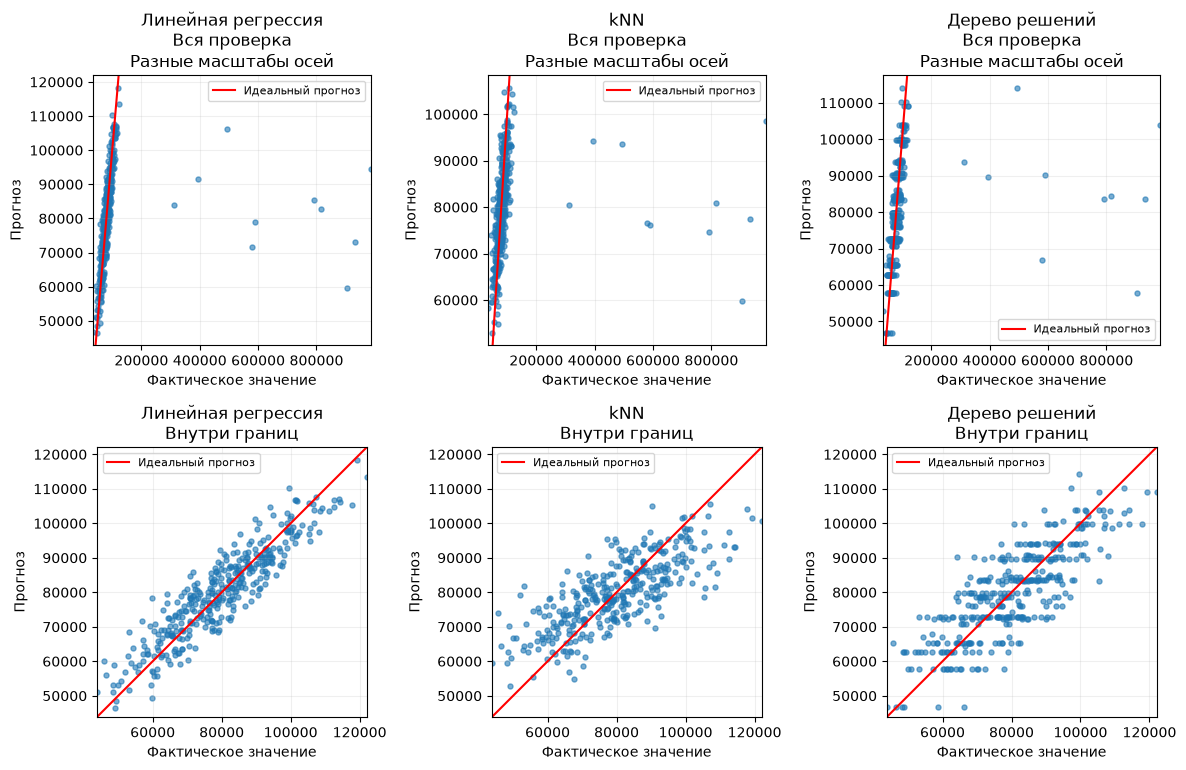

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7.8))

for col, name in enumerate(estimators):
    prediction = salary_predictions[name]

    fact_prediction(
        axes[0, col],
        y_valid,
        prediction,
        name + '\nВся проверка\nРазные масштабы осей'
    )
    padding = (prediction.max() - prediction.min()) * 0.05
    axes[0, col].set_ylim(prediction.min() - padding, prediction.max() + padding)
    axes[0, col].set_aspect('auto')

    fact_prediction(
        axes[1, col],
        y_valid.loc[keep_valid],
        prediction.loc[keep_valid],
        name + '\nВнутри границ'
    )

fig.tight_layout()
plt.show()

# 4 Выводы по результатам

In [12]:
best_simple = simple_metrics.sort_values('MAE').iloc[0]
best_poly = poly_metrics.loc[poly_metrics['Степень'] == best_degree].iloc[0]
best_salary = salary_metrics.iloc[:3].sort_values('MAE').iloc[0]

display(Markdown(f'''
Для данных var8 построены линейные и полиномиальные модели. Среди двух прямых точнее оказалась модель по {best_simple['Признак']}: MAE = {best_simple['MAE']:.5f}. Для x1 полином описал изгиб лучше прямой. По перекрёстной проверке выбрана степень {best_degree}, но её преимущество над степенью 2 оказалось небольшим.

В задаче прогноза зарплаты исследованы данные {len(salary)} сотрудников. Из обучающей выборки удалено {len(X_train_raw) - len(X_train)} выбросов зарплаты. Категории переведены в числа, числовые признаки стандартизированы, обучающие зарплаты нормализованы от 0 до 1. По линейной модели наиболее заметные связи с зарплатой имеют опыт, предыдущий доход, образование и сфера работы. При одинаковых остальных признаках дополнительный год опыта повышает прогноз на {per_unit['experience']:.2f}, а PhD по сравнению с Bachelor повышает его на {effects['cat__education_PhD']:.2f}.

Из трёх основных методов меньшую среднюю абсолютную ошибку дала модель «{best_salary['Модель']}»: MAE = {best_salary['MAE']:.2f} в исходных единицах зарплаты. Значение R² = {best_salary['R2']:.5f} показывает, что на полной проверочной выборке модель плохо объясняет разброс зарплат. Основная проблема связана с очень высокими зарплатами: модель значительно их занижает. Поэтому результаты позволяют описать связи признаков с обычным диапазоном зарплат, но не дают точного прогноза для всех сотрудников.
'''))


Для данных var8 построены линейные и полиномиальные модели. Среди двух прямых точнее оказалась модель по x2: MAE = 0.66122. Для x1 полином описал изгиб лучше прямой. По перекрёстной проверке выбрана степень 5, но её преимущество над степенью 2 оказалось небольшим.

В задаче прогноза зарплаты исследованы данные 1500 сотрудников. Из обучающей выборки удалено 37 выбросов зарплаты. Категории переведены в числа, числовые признаки стандартизированы, обучающие зарплаты нормализованы от 0 до 1. По линейной модели наиболее заметные связи с зарплатой имеют опыт, предыдущий доход, образование и сфера работы. При одинаковых остальных признаках дополнительный год опыта повышает прогноз на 906.23, а PhD по сравнению с Bachelor повышает его на 12326.70.

Из трёх основных методов меньшую среднюю абсолютную ошибку дала модель «Линейная регрессия»: MAE = 20699.03 в исходных единицах зарплаты. Значение R² = -0.00282 показывает, что на полной проверочной выборке модель плохо объясняет разброс зарплат. Основная проблема связана с очень высокими зарплатами: модель значительно их занижает. Поэтому результаты позволяют описать связи признаков с обычным диапазоном зарплат, но не дают точного прогноза для всех сотрудников.
